In [1]:
import numpy as np
import matplotlib.pyplot as plt
import time
import cv2

## Hồng Gấm – Demo 1: Ảnh là bảng số

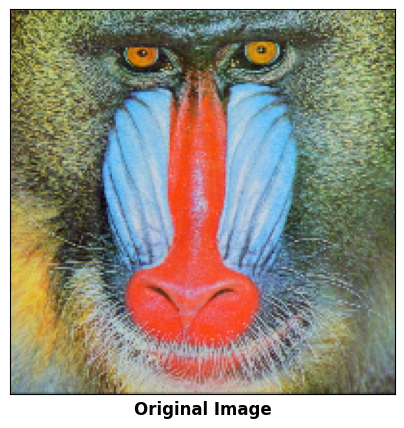

In [2]:
img = cv2.imread("../images/baboon.jpg")

if img is None:
    raise FileNotFoundError("Không tìm thấy baboon.jpg")

img = cv2.resize(img, (200, 200))
img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

plt.figure(figsize=(5, 5))
plt.imshow(img_rgb)
plt.xlabel("Original Image", fontsize=12, fontweight="bold")
plt.xticks([])
plt.yticks([])
plt.show()

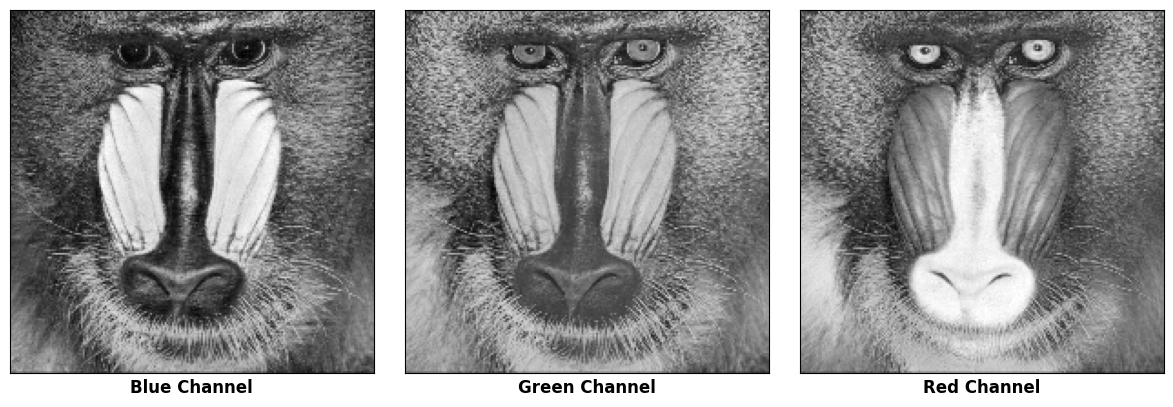

In [3]:
B, G, R = cv2.split(img)

channels = [B, G, R]
labels = ["Blue Channel", "Green Channel", "Red Channel"]

plt.figure(figsize=(12, 4))

for i in range(3):
    plt.subplot(1, 3, i + 1)
    plt.imshow(channels[i], cmap="gray", vmin=0, vmax=255)
    plt.xlabel(labels[i], fontsize=12, fontweight="bold")
    plt.xticks([])
    plt.yticks([])

plt.tight_layout()
plt.show()

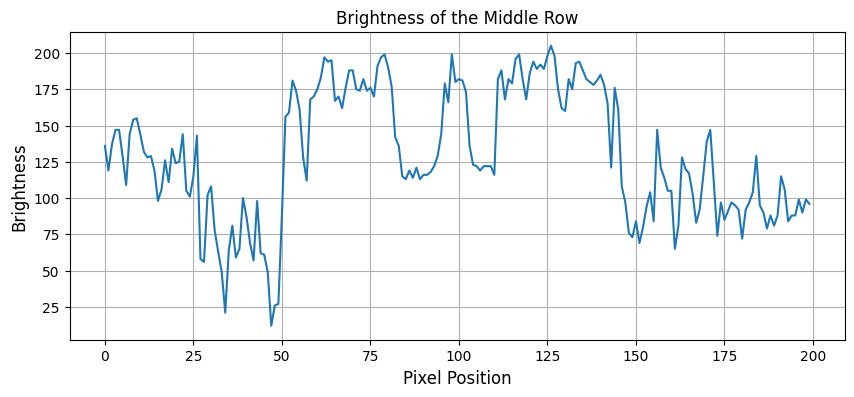

In [4]:
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

row = gray.shape[0] // 2

plt.figure(figsize=(10, 4))
plt.plot(gray[row, :])

plt.xlabel("Pixel Position", fontsize=12)
plt.ylabel("Brightness", fontsize=12)
plt.title("Brightness of the Middle Row")

plt.grid(True)
plt.show()

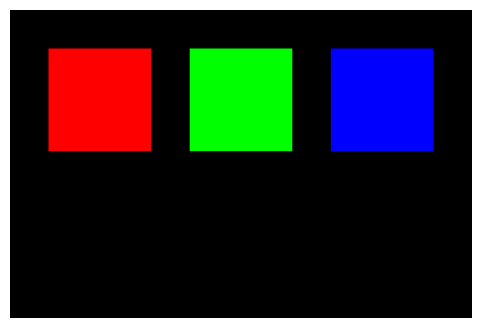

In [5]:

color_img = np.zeros((240, 360, 3), dtype=np.uint8)

color_img[30:110, 30:110] = (0, 0, 255)
color_img[30:110, 140:220] = (0, 255, 0)
color_img[30:110, 250:330] = (255, 0, 0)

plt.figure(figsize=(8, 4))
plt.imshow(cv2.cvtColor(color_img, cv2.COLOR_BGR2RGB))
plt.axis("off")
plt.show()

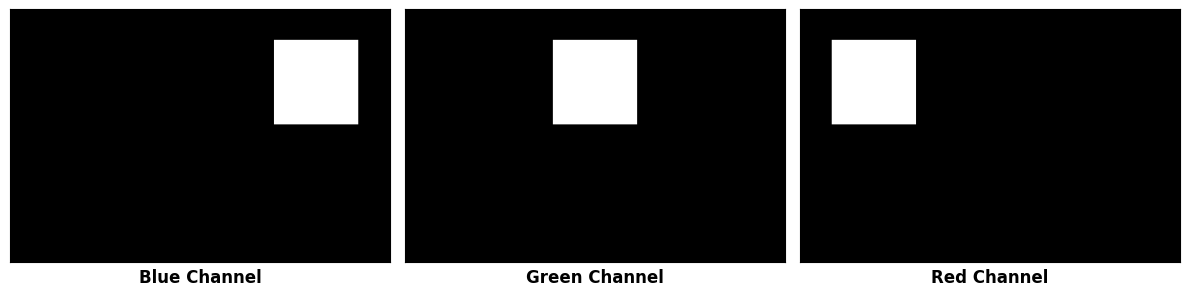

In [6]:

cB, cG, cR = cv2.split(color_img)

plt.figure(figsize=(12, 3))

for i, (ch, label) in enumerate(zip([cB, cG, cR], ["Blue Channel", "Green Channel", "Red Channel"])):
    plt.subplot(1, 3, i + 1)
    plt.imshow(ch, cmap="gray", vmin=0, vmax=255)
    plt.xlabel(label, fontsize=12, fontweight="bold")
    plt.xticks([])
    plt.yticks([])

plt.tight_layout()
plt.show()

## Demo 3a: convolve2d, lọc hộp, Gaussian

In [7]:
def convolve2d(image, kernel, padding="constant"):
    image = np.asarray(image, dtype=np.float64)
    kernel = np.asarray(kernel, dtype=np.float64)

    if image.ndim != 2 or kernel.ndim != 2:
        raise ValueError("Image và kernel phải là mảng 2 chiều")

    kh, kw = kernel.shape

    if kh % 2 == 0 or kw % 2 == 0:
        raise ValueError("Kernel phải có kích thước lẻ")

    if padding not in ("constant", "reflect", "edge"):
        raise ValueError("Padding không hợp lệ")

    ph, pw = kh // 2, kw // 2

    padded = np.pad(
        image,
        ((ph, ph), (pw, pw)),
        mode=padding
    )

    flipped = np.flip(kernel, axis=(0, 1))

    h, w = image.shape
    output = np.zeros((h, w), dtype=np.float64)

    for i in range(h):
        for j in range(w):
            region = padded[i:i+kh, j:j+kw]
            output[i, j] = np.sum(region * flipped)

    return output

In [8]:

test_image = np.arange(1, 26, dtype=np.float64).reshape(5, 5)

test_kernel = np.array([
    [1, 2, 3],
    [0, 4, 5],
    [6, 7, 8]
], dtype=np.float64) / 36

border_types = {
    "constant": cv2.BORDER_CONSTANT,
    "reflect": cv2.BORDER_REFLECT_101,
    "edge": cv2.BORDER_REPLICATE
}

for padding, border in border_types.items():
    custom_result = convolve2d(
        test_image,
        test_kernel,
        padding
    )

    opencv_result = cv2.filter2D(
        test_image,
        ddepth=-1,
        kernel=np.flip(test_kernel, axis=(0, 1)),
        borderType=border
    )

    max_error = np.max(
        np.abs(custom_result - opencv_result)
    )

    print(f"{padding}: max error = {max_error:.12f}")

constant: max error = 0.000000000000
reflect: max error = 0.000000000000
edge: max error = 0.000000000000


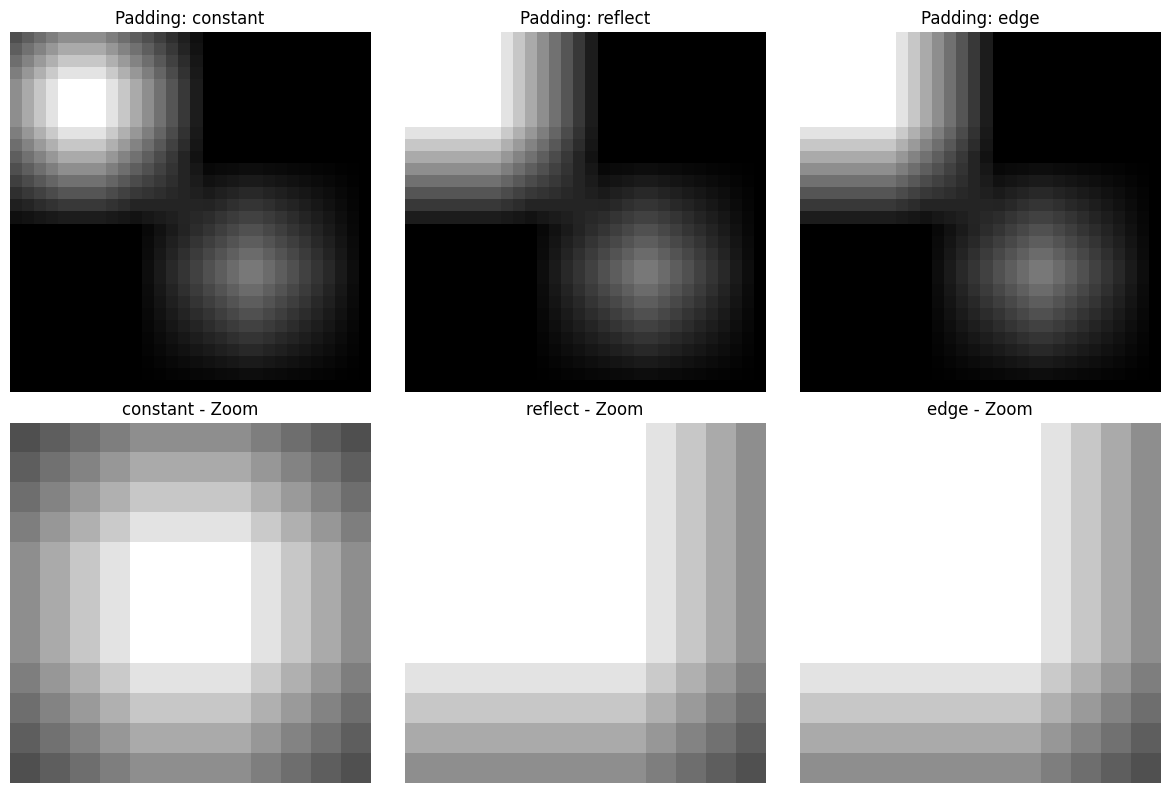

In [9]:

test_img = np.zeros((30, 30), dtype=np.float64)
test_img[:12, :12] = 255
test_img[15:25, 15:25] = 120

kernel = np.ones((9, 9), dtype=np.float64) / 81

results = {
    mode: convolve2d(test_img, kernel, mode)
    for mode in ("constant", "reflect", "edge")
}

fig, axes = plt.subplots(2, 3, figsize=(12, 8))

for col, (mode, result) in enumerate(results.items()):
    axes[0, col].imshow(
        result,
        cmap="gray",
        vmin=0,
        vmax=255
    )
    axes[0, col].set_title(f"Padding: {mode}")
    axes[0, col].axis("off")

    axes[1, col].imshow(
        result[:12, :12],
        cmap="gray",
        vmin=0,
        vmax=255,
        interpolation="nearest"
    )
    axes[1, col].set_title(f"{mode} - Zoom")
    axes[1, col].axis("off")

plt.tight_layout()
plt.show()

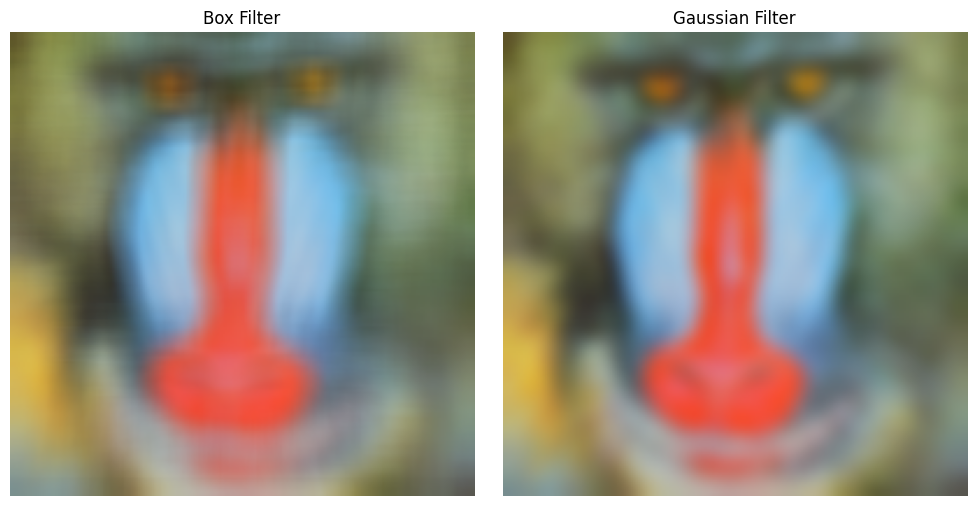

In [10]:

box_kernel = np.ones((15, 15), dtype=np.float64) / 225

g = cv2.getGaussianKernel(15, 4)
gaussian_kernel = g @ g.T

box_channels = [
    convolve2d(img[:, :, c], box_kernel, "reflect")
    for c in range(3)
]

gaussian_channels = [
    convolve2d(img[:, :, c], gaussian_kernel, "reflect")
    for c in range(3)
]

box_blur = np.clip(
    np.round(cv2.merge(box_channels)), 0, 255
).astype(np.uint8)

gaussian_blur = np.clip(
    np.round(cv2.merge(gaussian_channels)), 0, 255
).astype(np.uint8)

fig, axes = plt.subplots(1, 2, figsize=(10, 5))

axes[0].imshow(cv2.cvtColor(box_blur, cv2.COLOR_BGR2RGB))
axes[0].set_title("Box Filter")
axes[0].axis("off")

axes[1].imshow(cv2.cvtColor(gaussian_blur, cv2.COLOR_BGR2RGB))
axes[1].set_title("Gaussian Filter")
axes[1].axis("off")

plt.tight_layout()
plt.show()

In [11]:

opencv_box = cv2.blur(img, (15, 15), borderType=cv2.BORDER_REFLECT_101)
opencv_gaussian = cv2.GaussianBlur(img, (15, 15), 4, borderType=cv2.BORDER_REFLECT_101)

box_error = np.max(np.abs(box_blur.astype(int) - opencv_box.astype(int)))
gaussian_error = np.max(np.abs(gaussian_blur.astype(int) - opencv_gaussian.astype(int)))

print(f"Box filter vs cv2.blur: max error = {box_error}")
print(f"Gaussian vs cv2.GaussianBlur: max error = {gaussian_error}")

Box filter vs cv2.blur: max error = 0
Gaussian vs cv2.GaussianBlur: max error = 1


In [12]:

cv2.imwrite("../images/box_blur.jpg", box_blur)
cv2.imwrite("../images/gaussian_blur.jpg", gaussian_blur)

True

## KT3 – Thí nghiệm Hough

In [13]:
def create_line_image(segments, size=400):
    if int(size) != size or size < 2:
        raise ValueError("size phải là số nguyên >= 2")
    size = int(size)

    image = np.zeros((size, size), dtype=np.uint8)
    answers = []
    image_center = np.array([(size - 1) / 2, (size - 1) / 2])

    for rho0, theta0, length in segments:
        if length <= 0:
            raise ValueError("Độ dài đoạn thẳng phải dương")

        theta = np.deg2rad(theta0)

        normal = np.array([np.cos(theta), np.sin(theta)])
        direction = np.array([-np.sin(theta), np.cos(theta)])

        # Tâm đoạn = hình chiếu của tâm ảnh lên đường x cosθ + y sinθ = ρ
        foot = normal * rho0
        center = foot + direction * np.dot(image_center - foot, direction)

        p1 = center - direction * length / 2
        p2 = center + direction * length / 2

        # Đi từng pixel theo trục thay đổi nhiều hơn, làm tròn trục còn lại
        if abs(direction[0]) >= abs(direction[1]):
            xs = np.arange(np.ceil(min(p1[0], p2[0])), np.floor(max(p1[0], p2[0])) + 1)
            ys = p1[1] + (xs - p1[0]) * direction[1] / direction[0]
        else:
            ys = np.arange(np.ceil(min(p1[1], p2[1])), np.floor(max(p1[1], p2[1])) + 1)
            xs = p1[0] + (ys - p1[1]) * direction[0] / direction[1]

        xs = np.rint(xs).astype(int)
        ys = np.rint(ys).astype(int)

        if len(xs) == 0:
            raise ValueError("Đoạn thẳng quá ngắn, không vẽ được pixel nào")
        if xs.min() < 0 or xs.max() >= size or ys.min() < 0 or ys.max() >= size:
            raise ValueError("Đoạn thẳng nằm ngoài ảnh")

        image[ys, xs] = 255
        answers.append((rho0, theta0, length))

    return image, answers

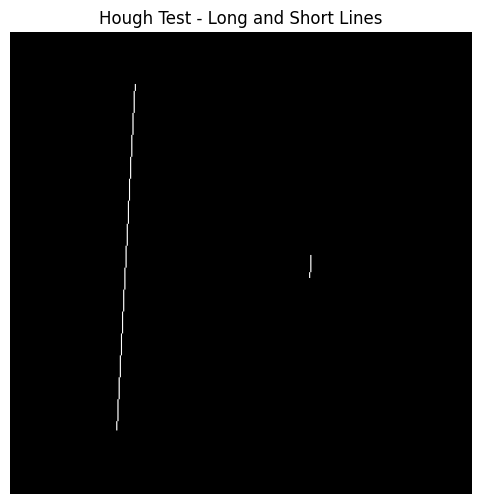

Đoạn 1: rho = 110, theta = 3°, length = 300px
Đoạn 2: rho = 270, theta = 3°, length = 20px


In [14]:
segments = [
    (110, 3, 300),
    (270, 3, 20)
]

hough_image, answers = create_line_image(segments)

cv2.imwrite("../images/hough_test.png", hough_image)

plt.figure(figsize=(6, 6))
plt.imshow(hough_image, cmap="gray", vmin=0, vmax=255)
plt.title("Hough Test - Long and Short Lines")
plt.axis("off")
plt.show()

for i, (rho, theta, length) in enumerate(answers, 1):
    print(f"Đoạn {i}: rho = {rho}, theta = {theta}°, length = {length}px")

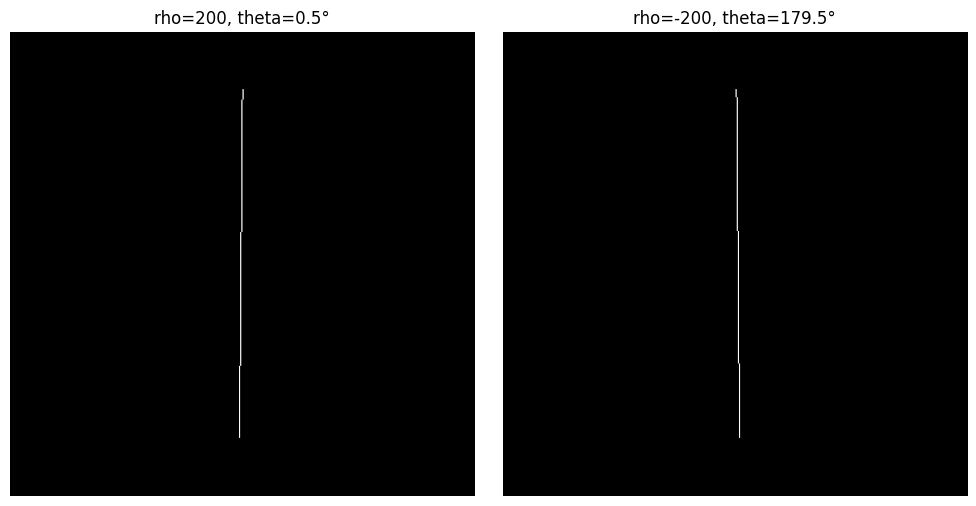

In [15]:
angle_tests = [
    (200, 0.5, 300),
    (-200, 179.5, 300)
]

fig, axes = plt.subplots(1, 2, figsize=(10, 5))

for ax, (rho, theta, length) in zip(axes, angle_tests):
    image, answer = create_line_image([(rho, theta, length)])

    filename = f"../images/hough_angle_{str(theta).replace('.', '_')}.png"
    cv2.imwrite(filename, image)

    ax.imshow(image, cmap="gray", vmin=0, vmax=255)
    ax.set_title(f"rho={rho}, theta={theta}°")
    ax.axis("off")

plt.tight_layout()
plt.show()

In [16]:
def angle_error(theta_true, theta_detected):
    difference = abs(theta_true - theta_detected) % 180
    return min(difference, 180 - difference)


def rho_error(rho_true, theta_true, rho_detected, theta_detected):
    t1 = np.deg2rad(theta_true)
    t2 = np.deg2rad(theta_detected)

    n1 = np.array([np.cos(t1), np.sin(t1)])
    n2 = np.array([np.cos(t2), np.sin(t2)])

    if np.dot(n1, n2) < 0:
        rho_detected = -rho_detected

    return abs(rho_true - rho_detected)


print("Sai số góc 3° và 5°:", angle_error(3, 5))
print("Sai số góc 0.5° và 179.5°:", angle_error(0.5, 179.5))
print("Sai số rho khi quấn vòng:", rho_error(200, 0.5, -200, 180.5))

Sai số góc 3° và 5°: 2
Sai số góc 0.5° và 179.5°: 1.0
Sai số rho khi quấn vòng: 0


In [17]:
def check_hough(image, rho_true, theta_true, threshold):
    lines = cv2.HoughLines(image, 1, np.pi / 360, threshold)

    if lines is None:
        print("Không phát hiện được đường thẳng")
        return

    rho_detected, theta = lines[0][0]
    theta_detected = np.rad2deg(theta)

    e_theta = angle_error(theta_true, theta_detected)
    e_rho = rho_error(rho_true, theta_true, rho_detected, theta_detected)

    print(f"Đáp án: rho={rho_true}, theta={theta_true}°")
    print(f"Phát hiện: rho={rho_detected:.2f}, theta={theta_detected:.2f}°")
    print(f"Sai số góc: {e_theta:.2f}°")
    print(f"Sai số rho: {e_rho:.2f}px")


for rho, theta, length in angle_tests:
    image, _ = create_line_image([(rho, theta, length)])
    print(f"\nKiểm thử theta={theta}°")
    check_hough(image, rho, theta, 100)


Kiểm thử theta=0.5°
Đáp án: rho=200, theta=0.5°
Phát hiện: rho=200.00, theta=0.50°
Sai số góc: 0.00°
Sai số rho: 0.00px

Kiểm thử theta=179.5°
Đáp án: rho=-200, theta=179.5°
Phát hiện: rho=-200.00, theta=179.50°
Sai số góc: 0.00°
Sai số rho: 0.00px
